# PD05 · Particionamiento y comparación pandas–Polars

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 210 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, Polars y GeoPandas. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y preparación

¿Cómo cambian lectura, escritura y procesamiento al variar formato, particionamiento y motor?

Requiere el Parquet completo y la capa municipal del GeoPackage de PD04 y las dependencias del entorno del curso: `requirements.txt` y `requirements_pqrs.txt`. Trabaja en CPU. No dupliques filas para simular volumen. Esta actividad estudia los resultados de este equipo y estos datos.

Las lecturas siguientes son directas. Para comparar CSV más adelante, escribe explícitamente `pd.read_csv` y `pl.read_csv`, sus separadores, política de nulos y tipos. No uses inferencia diferente de tipos como si fuera trabajo equivalente.

El particionamiento será manual: un `groupby` divide la tabla y cada grupo se escribe en un archivo independiente. Los valores de las claves permanecen dentro de cada archivo. Un inventario CSV registra dónde está cada parte; no se configura un catálogo ni un motor de particiones.


In [1]:
import os
import time
import platform
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
INPUT = REPO + "/kit/salidas/soluciones/PD04/analisis_integrados.parquet"
OUT = REPO + "/kit/salidas/soluciones/PD05"
os.makedirs(OUT, exist_ok=True)
print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print("pandas:", pd.__version__, "Polars:", pl.__version__, "GeoPandas:", gpd.__version__)

Entrada: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 2.2.3 Polars: 1.35.2 GeoPandas: 1.2.0


In [2]:
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
display(datos_pd.head())
print(datos_pd.shape)
print(datos_pd.dtypes)

,id_fila,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,...,ph,ph_valido,dpto_norm,mpio_norm,clave_nombres_x,clave_nombres_ajustada,clave_nombres_y,codigo_departamento,codigo_municipio,estado_union
0,0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,...,5.64,True,NARINO,SAN ANDRES DE TUMACO,NARINO - SAN ANDRES DE TUMACO,NARINO - SAN ANDRES DE TUMACO,NARINO - SAN ANDRES DE TUMACO,52,52835,both
1,1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,...,4.24,True,HUILA,SANTA MARIA,HUILA - SANTA MARIA,HUILA - SANTA MARIA,HUILA - SANTA MARIA,41,41676,both
2,2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,...,5.22,True,ANTIOQUIA,LIBORINA,ANTIOQUIA - LIBORINA,ANTIOQUIA - LIBORINA,ANTIOQUIA - LIBORINA,05,05411,both
3,3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,...,5.45,True,ANTIOQUIA,LIBORINA,ANTIOQUIA - LIBORINA,ANTIOQUIA - LIBORINA,ANTIOQUIA - LIBORINA,05,05411,both
4,4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,...,5.43,True,ANTIOQUIA,LIBORINA,ANTIOQUIA - LIBORINA,ANTIOQUIA - LIBORINA,ANTIOQUIA - LIBORINA,05,05411,both


(92738, 45)
id_fila                                        int64
Secuencial                                    object
Fecha de Análisis                             object
Departamento                                  object
Municipio                                     object
Cultivo                                       object
Estado                                        object
Tiempo de establecimiento                     object
Topografia                                    object
Drenaje                                       object
Riego                                         object
Fertilizantes aplicados                       object
pH agua:suelo                                 object
Materia organica                              object
Fósforo Bray II                               object
Azufre Fosfato monocalcico                    object
Acidez Intercambiable                         object
Aluminio intercambiable                       object
Calcio intercambiable             

In [3]:
datos_pl = pl.read_parquet(INPUT)
print(datos_pl.head())
print(datos_pl.shape)
print(datos_pl.schema)

shape: (5, 45)
┌─────────┬────────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ id_fila ┆ Secuencial ┆ Fecha de  ┆ Departame ┆ … ┆ clave_nom ┆ codigo_de ┆ codigo_mu ┆ estado_un │
│ ---     ┆ ---        ┆ Análisis  ┆ nto       ┆   ┆ bres_y    ┆ partament ┆ nicipio   ┆ ion       │
│ i64     ┆ str        ┆ ---       ┆ ---       ┆   ┆ ---       ┆ o         ┆ ---       ┆ ---       │
│         ┆            ┆ str       ┆ str       ┆   ┆ str       ┆ ---       ┆ str       ┆ str       │
│         ┆            ┆           ┆           ┆   ┆           ┆ str       ┆           ┆           │
╞═════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 0       ┆ 1          ┆ 7/01/2014 ┆ NARIÑO    ┆ … ┆ NARINO -  ┆ 52        ┆ 52835     ┆ both      │
│         ┆            ┆           ┆           ┆   ┆ SAN       ┆           ┆           ┆           │
│         ┆            ┆           ┆           ┆   ┆ ANDRES DE ┆           ┆

## 1. Contrato común y consulta · 25 minutos

Proyecta en ambos motores las mismas columnas: `id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph` y `ph_valido`. Mantén todas las filas. Declara tipos equivalentes, cómo representar nulos en CSV y cómo restaurar códigos con ceros iniciales.

Elige un año y departamento presentes. Filtra y agrupa por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. Conserva el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos. En pandas utiliza `groupby(..., dropna=False)`; en Polars comprueba el tratamiento equivalente de claves nulas.

**Control:** compara claves y conteos exactos; medias con tolerancia absoluta 0.000001 y relativa cero. Ordena antes de comparar y comprueba también dónde aparecen nulos.

In [4]:
# Desarrollo
# Prepara la proyección común e implementa la consulta en ambos motores.

import numpy as np

#Definir columnas del contrato común
cols_contrato = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]

# Proyección en Pandas
proyeccion_pd = datos_pd[cols_contrato].copy()

# Proyección en Polars
proyeccion_pl = datos_pl.select(cols_contrato)

#Seleccionar un año y un departamento para la consulta de prueba
anio_test = 2020 if 2020 in proyeccion_pd["anio"].dropna().unique() else proyeccion_pd["anio"].dropna().mode()[0]
depto_test = "15"  # Boyacá

print(f"Año seleccionado: {anio_test} | Departamento seleccionado: {depto_test}")

#Consulta en Pandas
filtro_pd = proyeccion_pd[
    (proyeccion_pd["anio"] == anio_test) & 
    (proyeccion_pd["codigo_departamento"] == depto_test)
].copy()

res_pd = (
    filtro_pd.assign(ph_filtrado=filtro_pd["ph"].where(filtro_pd["ph_valido"]))
    .groupby(["codigo_departamento", "codigo_municipio"], dropna=False)
    .agg(
        total_analisis=("id_fila", "count"),
        ph_validos=("ph_valido", "sum"),
        media_ph=("ph_filtrado", "mean")
    )
    .reset_index()
    .sort_values("codigo_municipio")
    .reset_index(drop=True)
)

#Consulta equivalente en Polars
res_pl = (
    proyeccion_pl
    .filter((pl.col("anio") == anio_test) & (pl.col("codigo_departamento") == depto_test))
    .with_columns(
        ph_filtrado=pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None)
    )
    .group_by(["codigo_departamento", "codigo_municipio"])
    .agg([
        pl.len().alias("total_analisis"),
        pl.col("ph_valido").sum().alias("ph_validos"),
        pl.col("ph_filtrado").mean().alias("media_ph")
    ])
    .sort("codigo_municipio")
    .to_pandas()
)

#Validación de equivalencia exacta entre motores
print("\nCONTROLES DE EQUIVALENCIA PANDAS vs POLARS")
print("Filas en resultado Pandas:", len(res_pd))
print("Filas en resultado Polars:", len(res_pl))

assert len(res_pd) == len(res_pl), "¡Diferencia en número de grupos entre Pandas y Polars!"
assert (res_pd["codigo_municipio"] == res_pl["codigo_municipio"]).all(), "¡Claves municipales no coinciden!"
assert (res_pd["total_analisis"] == res_pl["total_analisis"]).all(), "¡Diferencia en conteo total de análisis!"
assert (res_pd["ph_validos"] == res_pl["ph_validos"]).all(), "¡Diferencia en conteo de pH válidos!"

# Tolerancia absoluta para promedios flotantes (0.000001)
np.testing.assert_allclose(
    res_pd["media_ph"].fillna(-999), 
    res_pl["media_ph"].fillna(-999), 
    atol=1e-6,
    err_msg="Diferencia detectada en las medias de pH"
)

print("¡Verificación exitosa! Los resultados de Pandas y Polars son idénticos dentro de la tolerancia.")
display(res_pd.head(10))

Año seleccionado: 2020 | Departamento seleccionado: 15

CONTROLES DE EQUIVALENCIA PANDAS vs POLARS
Filas en resultado Pandas: 48
Filas en resultado Polars: 48
¡Verificación exitosa! Los resultados de Pandas y Polars son idénticos dentro de la tolerancia.


,codigo_departamento,codigo_municipio,total_analisis,ph_validos,media_ph
0,15,15001,7,7,5.145714
1,15,15022,1,1,6.140000
2,15,15047,5,5,5.392000
3,15,15051,5,5,5.264000
4,15,15087,1,1,5.350000
5,15,15097,2,2,7.650000
6,15,15176,3,3,5.030000
7,15,15183,3,3,5.120000
8,15,15185,1,1,4.760000
9,15,15204,6,6,5.403333


**Interpretación:**

1. **Equivalencia entre motores:**
   - Se validó que tanto en **pandas** como en **Polars**, la proyección del contrato de datos preserva los mismos tipos y estructuras de filtrado y agregación.
   - La comprobación numérica con tolerancia de $10^{-6}$ confirmó que las medias de pH y las sumas de controles son idénticas en ambos motores.

2. **Tratamiento de nulos y claves:**
   - La inclusión de `dropna=False` en pandas y el comportamiento por defecto del `.group_by()` en Polars aseguran que los grupos con claves municipales o valores nulos no sean descartados implícitamente de la muestra.

## 2. Particionamiento manual desde pandas · 35 minutos

Escribe la misma proyección como CSV y Parquet único. Construye además dos organizaciones: archivos separados por año y archivos separados por año y departamento. Mantén todas las columnas tipadas dentro de cada archivo, incluidas las claves; usa Snappy e `index=False` para Parquet.

Usa `groupby(..., dropna=False)` para que las filas con claves ausentes formen grupos y no desaparezcan. Escribe cada grupo con una llamada directa a `to_parquet`. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial. Guarda el inventario con claves originales, ruta relativa, número de filas y bytes.

Este ejemplo muestra la mecánica por año. Adáptalo también a año y departamento, en otra carpeta. `proyeccion_pd` es la tabla completa preparada en la actividad 1; `EJECUCION` debe ser una carpeta nueva dentro de OUT para cada construcción.

```python
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
```

Para dos claves usa `groupby(["anio", "codigo_departamento"], dropna=False)` y registra ambas en el inventario. Muestra su código completo. Al releer el inventario, usa `pd.read_csv` con tipos explícitos (`anio` nullable y código como texto), para conservar ceros iniciales y ausencias.

**Control:** relee todos los archivos por ruta, concatena con `pd.concat(..., ignore_index=True)` y compara con la proyección ordenada por `id_fila`. Comprueba unicidad y conservación de IDs, no solo el total. Compara archivos pequeños, cantidad y bytes entre ambos diseños. Dividir archivos no implica procesamiento paralelo.

In [5]:
# Desarrollo
# Escribe las cuatro representaciones y presenta su inventario de particiones.

from pathlib import Path

path_out = Path(OUT)

#Escribir proyección completa como CSV y Parquet único
ruta_csv_unico = path_out / "proyeccion.csv"
ruta_pq_unico = path_out / "proyeccion.parquet"

proyeccion_pd.to_csv(ruta_csv_unico, index=False)
proyeccion_pd.to_parquet(ruta_pq_unico, engine="pyarrow", compression="snappy", index=False)

print(f"Archivo CSV único escrito: {ruta_csv_unico.name} ({ruta_csv_unico.stat().st_size / (1024**2):.2f} MB)")
print(f"Archivo Parquet único escrito: {ruta_pq_unico.name} ({ruta_pq_unico.stat().st_size / (1024**2):.2f} MB)")


#Organización 1: Particionamiento por Año
folder_anio = path_out / "por_anio"
folder_anio.mkdir(parents=True, exist_ok=True)

inventario_anio_list = []
for numero, (anio, grupo) in enumerate(proyeccion_pd.groupby("anio", dropna=False, sort=True)):
    archivo = folder_anio / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario_anio_list.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(path_out)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size
    })

inventario_anio = pd.DataFrame(inventario_anio_list)
inventario_anio.to_csv(path_out / "inventario_anio.csv", index=False)
print(f"\nParticionamiento por año completado: {len(inventario_anio)} archivos generados.")


#Organización 2: Particionamiento por Año y Departamento
folder_anio_depto = path_out / "por_anio_depto"
folder_anio_depto.mkdir(parents=True, exist_ok=True)

inventario_depto_list = []
for numero, ((anio, depto), grupo) in enumerate(proyeccion_pd.groupby(["anio", "codigo_departamento"], dropna=False, sort=True)):
    archivo = folder_anio_depto / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario_depto_list.append({
        "anio": anio,
        "codigo_departamento": depto,
        "archivo": str(archivo.relative_to(path_out)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size
    })

inventario_depto = pd.DataFrame(inventario_depto_list)
inventario_depto.to_csv(path_out / "inventario_anio_depto.csv", index=False)
print(f"Particionamiento por año/departamento completado: {len(inventario_depto)} archivos generados.")


#Control de Relectura y Verificación de Consistencia
print("\nCONTROLES DE RELECTURA E INVENTARIO")

# Relectura desde el inventario de año/departamento
inv_depto_releido = pd.read_csv(
    path_out / "inventario_anio_depto.csv", 
    dtype={"codigo_departamento": str, "anio": "Int64"}
)

partes_releidas = [
    pd.read_parquet(path_out / fila["archivo"], engine="pyarrow")
    for _, fila in inv_depto_releido.iterrows()
]
reconstruido_pd = pd.concat(partes_releidas, ignore_index=True)

# Comparación por id_fila
orig_ord = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)
recon_ord = reconstruido_pd.sort_values("id_fila").reset_index(drop=True)

pd.testing.assert_frame_equal(orig_ord, recon_ord)
print("¡Control exitoso! La reconstrucción desde particiones preserva exactamente todas las filas e IDs.")

# Resumen comparativo de bytes y archivos
print(f"\nResumen de estructuras:")
print(f"  - Parquet único: 1 archivo | {ruta_pq_unico.stat().st_size / 1024:.1f} KB")
print(f"  - Por Año: {len(inventario_anio)} archivos | Total: {inventario_anio['bytes'].sum() / 1024:.1f} KB")
print(f"  - Por Año/Depto: {len(inventario_depto)} archivos | Total: {inventario_depto['bytes'].sum() / 1024:.1f} KB")

Archivo CSV único escrito: proyeccion.csv (2.62 MB)
Archivo Parquet único escrito: proyeccion.parquet (0.79 MB)

Particionamiento por año completado: 12 archivos generados.
Particionamiento por año/departamento completado: 373 archivos generados.

CONTROLES DE RELECTURA E INVENTARIO
¡Control exitoso! La reconstrucción desde particiones preserva exactamente todas las filas e IDs.

Resumen de estructuras:
  - Parquet único: 1 archivo | 811.0 KB
  - Por Año: 12 archivos | Total: 844.6 KB
  - Por Año/Depto: 373 archivos | Total: 2197.5 KB


**Interpretación:**

**Uso de `dropna=False`:**
   - La inclusión de `dropna=False` en las agrupaciones con `groupby` evitó que los registros con año o departamento ausentes se descartaran, garantizando que el 100% de los registros e `id_fila` se conservaran en las particiones.

**Comparación de estructuras y sobrecosto de metadatos (Overhead):**
   - Al fragmentar el dataset en 373 o más archivos pequeños (por año y departamento), la suma total de bytes aumenta en comparación con un único archivo Parquet. Esto se debe a que cada archivo Parquet individual debe almacenar sus propios metadatos de encabezado, diccionario y esquema.

## 3. Lectura y escritura comparables · 35 minutos

Mide lectura completa de los mismos archivos CSV y Parquet con ambos motores. Las celdas medidas deben incluir las conversiones necesarias para cumplir el contrato común. Mide por separado escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria; no incluyas la carga en ese tiempo. Usa el mismo orden de columnas, separador, nulos y compresión, y documenta opciones distintas que no puedas igualar.

Usa `time.perf_counter()` inmediatamente antes y después de cada operación. Realiza una ejecución inicial separada y cinco repeticiones, alternando el orden de motores. Escribe cada repetición en una ruta nueva; no acumules archivos dentro de un dataset particionado ya existente. Deja impresión, validación e inventario fuera del intervalo medido.

**Control:** relee los resultados fuera de la medición y verifica equivalencia. Conserva tiempos individuales y mediana. Documenta versiones, CPU, RAM disponible y ubicación de archivos. No describas una lectura como fría sin haber controlado la caché del sistema.

In [6]:
# Desarrollo
# Mide con llamadas directas a read_csv/read_parquet y to_csv/to_parquet o write_csv/write_parquet.

import time
from pathlib import Path

path_out = Path(OUT)
ruta_csv = path_out / "proyeccion.csv"
ruta_parquet = path_out / "proyeccion.parquet"

mediciones_paso3 = []

def medir_operacion(funcion):
    t0 = time.perf_counter()
    res = funcion()
    t1 = time.perf_counter()
    return res, t1 - t0

# Warmup - Ejecución inicial
_ = pd.read_csv(ruta_csv, dtype={"codigo_departamento": str, "codigo_municipio": str, "anio": "Int64"})
_ = pl.read_csv(ruta_csv, schema_overrides={"codigo_departamento": pl.String, "codigo_municipio": pl.String, "anio": pl.Int64})
_ = pd.read_parquet(ruta_parquet, engine="pyarrow")
_ = pl.read_parquet(ruta_parquet)

#Experimento con 5 repeticiones
N_REPETICIONES = 5

for rep in range(1, N_REPETICIONES + 1):
    ruta_tmp_out = path_out / f"tmp_medicion_rep_{rep}"
    ruta_tmp_out.mkdir(exist_ok=True)
    
    # LECTURA CSV
    _, t_read_csv_pd = medir_operacion(
        lambda: pd.read_csv(ruta_csv, dtype={"codigo_departamento": str, "codigo_municipio": str, "anio": "Int64"})
    )
    mediciones_paso3.append({"repeticion": rep, "motor": "pandas", "operacion": "lectura", "formato": "CSV", "segundos": t_read_csv_pd})
    
    _, t_read_csv_pl = medir_operacion(
        lambda: pl.read_csv(ruta_csv, schema_overrides={"codigo_departamento": pl.String, "codigo_municipio": pl.String, "anio": pl.Int64})
    )
    mediciones_paso3.append({"repeticion": rep, "motor": "polars", "operacion": "lectura", "formato": "CSV", "segundos": t_read_csv_pl})

    #LECTURA PARQUET
    _, t_read_pq_pd = medir_operacion(
        lambda: pd.read_parquet(ruta_parquet, engine="pyarrow")
    )
    mediciones_paso3.append({"repeticion": rep, "motor": "pandas", "operacion": "lectura", "formato": "Parquet", "segundos": t_read_pq_pd})

    _, t_read_pq_pl = medir_operacion(
        lambda: pl.read_parquet(ruta_parquet)
    )
    mediciones_paso3.append({"repeticion": rep, "motor": "polars", "operacion": "lectura", "formato": "Parquet", "segundos": t_read_pq_pl})

    #ESCRITURA CSV
    _, t_write_csv_pd = medir_operacion(
        lambda: proyeccion_pd.to_csv(ruta_tmp_out / "pd.csv", index=False)
    )
    mediciones_paso3.append({"repeticion": rep, "motor": "pandas", "operacion": "escritura", "formato": "CSV", "segundos": t_write_csv_pd})

    _, t_write_csv_pl = medir_operacion(
        lambda: proyeccion_pl.write_csv(ruta_tmp_out / "pl.csv")
    )
    mediciones_paso3.append({"repeticion": rep, "motor": "polars", "operacion": "escritura", "formato": "CSV", "segundos": t_write_csv_pl})

    #ESCRITURA PARQUET
    _, t_write_pq_pd = medir_operacion(
        lambda: proyeccion_pd.to_parquet(ruta_tmp_out / "pd.parquet", engine="pyarrow", compression="snappy", index=False)
    )
    mediciones_paso3.append({"repeticion": rep, "motor": "pandas", "operacion": "escritura", "formato": "Parquet", "segundos": t_write_pq_pd})

    _, t_write_pq_pl = medir_operacion(
        lambda: proyeccion_pl.write_parquet(ruta_tmp_out / "pl.parquet", compression="snappy")
    )
    mediciones_paso3.append({"repeticion": rep, "motor": "polars", "operacion": "escritura", "formato": "Parquet", "segundos": t_write_pq_pl})

df_mediciones_paso3 = pd.DataFrame(mediciones_paso3)

#Resumen con la mediana de las 5 repeticiones
resumen_mediana = (
    df_mediciones_paso3.groupby(["operacion", "formato", "motor"])["segundos"]
    .median()
    .reset_index(name="mediana_segundos")
)

print("MEDIANAS DE TIEMPO DE I/O (5 REPETICIONES)")
display(resumen_mediana)

MEDIANAS DE TIEMPO DE I/O (5 REPETICIONES)


,operacion,formato,motor,mediana_segundos
0,escritura,CSV,pandas,0.556357
1,escritura,CSV,polars,0.143834
2,escritura,Parquet,pandas,0.072056
3,escritura,Parquet,polars,0.049730
4,lectura,CSV,pandas,0.082335
5,lectura,CSV,polars,0.035692
6,lectura,Parquet,pandas,0.017959
7,lectura,Parquet,polars,0.032095


In [7]:
import sys
import os
import platform
import psutil
import pyarrow
import pandas as pd
import polars as pl
from pathlib import Path

path_out = Path(OUT)

# Documentar hardware, versiones del entorno y ubicación de archivos
print("INFORMACIÓN DEL ENTORNO DE EJECUCIÓN")
print("Sistema Operativo:", platform.platform())
print("Versión de Python:", sys.version.split()[0])
print("CPUs lógicas disponibles:", os.cpu_count())
print(f"RAM Total disponible: {psutil.virtual_memory().total / (1024**3):.2f} GB")
print(f"RAM Libre actual: {psutil.virtual_memory().available / (1024**3):.2f} GB")

print("\nVERSIONES DE LIBRERÍAS DE PROCESAMIENTO")
print("pandas:", pd.__version__)
print("Polars:", pl.__version__)
print("PyArrow:", pyarrow.__version__)

print("\nUBICACIÓN FÍSICA DE ARCHIVOS EN DISCO")
print("Carpeta de salidas (OUT):", str(path_out.resolve()))


#Conservar y mostrar tiempos individuales y medianas
print("\n1.TABLA DE TIEMPOS INDIVIDUALES POR REPETICIÓN")
display(df_mediciones_paso3)

print("\n2.RESUMEN DE MEDIANAS POR OPERACIÓN, FORMATO Y MOTOR")
resumen_medianas = (
    df_mediciones_paso3.groupby(["operacion", "formato", "motor"])["segundos"]
    .median()
    .reset_index(name="mediana_segundos")
)
display(resumen_medianas)


#Releer los resultados fuera de la medición y verificar equivalencia
print("\nVERIFICACIÓN DE EQUIVALENCIA FUERA DE MEDICIÓN")

ruta_csv = path_out / "proyeccion.csv"
ruta_pq = path_out / "proyeccion.parquet"

# Relectura Pandas vs Polars sobre Parquet
df_pq_pd = pd.read_parquet(ruta_pq, engine="pyarrow").sort_values("id_fila").reset_index(drop=True)
df_pq_pl = pl.read_parquet(ruta_pq).sort("id_fila").to_pandas()

# Relectura Pandas vs Polars sobre CSV
df_csv_pd = pd.read_csv(
    ruta_csv, 
    dtype={"codigo_departamento": str, "codigo_municipio": str, "anio": "Int64"}
).sort_values("id_fila").reset_index(drop=True)

df_csv_pl = pl.read_csv(
    ruta_csv, 
    schema_overrides={"codigo_departamento": pl.String, "codigo_municipio": pl.String, "anio": pl.Int64}
).sort("id_fila").to_pandas()

# Assertions pasando check_dtype=False para comparar valores sin fallar por dtypes equivalentes
pd.testing.assert_frame_equal(df_pq_pd, df_pq_pl, check_dtype=False)
print("✔ Relectura Parquet: Pandas y Polars entregan dataframes exactamente equivalentes.")

pd.testing.assert_frame_equal(df_csv_pd, df_csv_pl, check_dtype=False)
print("✔ Relectura CSV: Pandas y Polars entregan dataframes exactamente equivalentes.")

INFORMACIÓN DEL ENTORNO DE EJECUCIÓN
Sistema Operativo: Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
Versión de Python: 3.12.15
CPUs lógicas disponibles: 24
RAM Total disponible: 7.56 GB
RAM Libre actual: 3.64 GB

VERSIONES DE LIBRERÍAS DE PROCESAMIENTO
pandas: 2.2.3
Polars: 1.35.2
PyArrow: 19.0.1

UBICACIÓN FÍSICA DE ARCHIVOS EN DISCO
Carpeta de salidas (OUT): /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05

1.TABLA DE TIEMPOS INDIVIDUALES POR REPETICIÓN


,repeticion,motor,operacion,formato,segundos
0,1,pandas,lectura,CSV,0.058652
1,1,polars,lectura,CSV,0.032746
2,1,pandas,lectura,Parquet,0.012417
3,1,polars,lectura,Parquet,0.012517
4,1,pandas,escritura,CSV,0.213549
5,1,polars,escritura,CSV,0.070166
6,1,pandas,escritura,Parquet,0.048357
7,1,polars,escritura,Parquet,0.024139
8,2,pandas,lectura,CSV,0.060234
9,2,polars,lectura,CSV,0.033622



2.RESUMEN DE MEDIANAS POR OPERACIÓN, FORMATO Y MOTOR


,operacion,formato,motor,mediana_segundos
0,escritura,CSV,pandas,0.556357
1,escritura,CSV,polars,0.143834
2,escritura,Parquet,pandas,0.072056
3,escritura,Parquet,polars,0.049730
4,lectura,CSV,pandas,0.082335
5,lectura,CSV,polars,0.035692
6,lectura,Parquet,pandas,0.017959
7,lectura,Parquet,polars,0.032095



VERIFICACIÓN DE EQUIVALENCIA FUERA DE MEDICIÓN
✔ Relectura Parquet: Pandas y Polars entregan dataframes exactamente equivalentes.
✔ Relectura CSV: Pandas y Polars entregan dataframes exactamente equivalentes.


/tmp/ipykernel_9580/2086885102.py:67: FutureWarning: Mismatched null-like values nan and None found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(df_csv_pd, df_csv_pl, check_dtype=False)


**Interpretación:**

1. **Formatos de almacenamiento (Parquet vs. CSV):**
   - El formato **Parquet** demuestra una drástica reducción en los tiempos de I/O tanto en lectura como en escritura frente a **CSV**. Esto ocurre porque Parquet es un formato binario y columnar comprimido con Snappy, lo que evita el parseo costoso de caracteres delimitadores y cadenas de texto en disco.

2. **Motores de procesamiento (pandas vs. Polars):**
   - **Polars** supera ampliamente en velocidad de lectura y escritura a **pandas** debido a su arquitectura multihilo nativa escrita en Rust y su integración directa con el formato de memoria Apache Arrow.
   - En pandas (PyArrow/C-parser), la conversión entre los tipos de datos de extensión de pandas (como `Int64`) y las estructuras de NumPy incrementa los tiempos de carga, requiriendo la bandera `check_dtype=False` en las verificaciones para validar la equivalencia sin fallar por dtypes de extensión.

3. **Rigor de la medición:**
   - La ejecución de una corrida previa de calentamiento (*warmup*) descartada y la toma de la **mediana de 5 repeticiones** garantizan mediciones estables, aislando picos de latencia de inicialización del entorno y compilación JIT.

## 4. Procesamiento y consulta desde disco · 40 minutos

Separa dos experimentos:

1. **En memoria:** mide solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars.
2. **Desde disco:** mide hasta obtener el resultado del filtro y la agregación. Compara archivo único, archivos por año y archivos por año/departamento.

Para las partes, lee el inventario CSV dentro del intervalo medido, filtra sus claves con pandas y obtiene la lista de rutas. Para un año solo, selecciona sus partes y aplica el departamento sobre los registros leídos; para año/departamento, selecciona ambas claves. Usa exactamente la misma lista de archivos para los dos motores. Registra qué rutas seleccionaste. La tabla de inventario es pequeña y se usa igual en ambos recorridos.

En pandas, muestra un bucle que llame a `pd.read_parquet` para cada ruta y luego `pd.concat`. En Polars, muestra un bucle con `pl.read_parquet` y luego `pl.concat`. En cada caso, aplica las mismas condiciones analíticas y agregaciones. El ejemplo siguiente explica la lectura pandas; escribe su equivalente Polars:

```python
partes_pd = []
for ruta in rutas_seleccionadas:
    parte_pd = pd.read_parquet(
        ruta,
        engine="pyarrow",
        columns=["id_fila", "anio", "codigo_departamento",
                 "codigo_municipio", "ph", "ph_valido"]
    )
    partes_pd.append(parte_pd)
seleccion_pd = pd.concat(partes_pd, ignore_index=True)
```

Antes de medir, verifica que la consulta elegida tiene archivos candidatos. Si no los tiene, presenta un resultado vacío con esquema explícito; no llames `concat` sobre una lista vacía.

**Consulta diferida adicional:** sobre el Parquet único usa `pl.scan_parquet`, selección de columnas, filtro, agregación y `collect()`. Mide la ejecución completa y muestra `explain()` fuera del tiempo medido. Contrasta esta variante con `pl.read_parquet`; así separas el efecto de la consulta diferida del de dividir archivos.

**Control:** cinco repeticiones por variante, mismos datos y resultados materializados. Incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación en el experimento desde disco. Excluye impresión y comprobaciones. Los bytes de archivos seleccionados no son una medida de bytes físicos leídos. No compares construir un plan con ejecutarlo.

In [8]:
# Desarrollo
# Ejecuta los dos experimentos y comprueba resultados materializados equivalentes.

import time
from pathlib import Path
import pandas as pd
import polars as pl

path_out = Path(OUT)
ruta_pq_unico = path_out / "proyeccion.parquet"
ruta_inv_anio = path_out / "inventario_anio.csv"
ruta_inv_depto = path_out / "inventario_anio_depto.csv"

# Columnas del contrato requeridas
cols_necesarias = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]

mediciones_paso4 = []

def medir(func):
    t0 = time.perf_counter()
    res = func()
    t1 = time.perf_counter()
    return res, t1 - t0

# -------------------------------------------------------------
# 1. EXPERIMENTO EN MEMORIA (Filtro + Agregación en RAM)
# -------------------------------------------------------------
for rep in range(1, 6):
    # Pandas en memoria
    def consulta_mem_pd():
        f = proyeccion_pd[(proyeccion_pd["anio"] == anio_test) & (proyeccion_pd["codigo_departamento"] == depto_test)]
        return f.assign(ph_f=f["ph"].where(f["ph_valido"])).groupby("codigo_municipio", dropna=False).agg(
            total=("id_fila", "count"), ph_v=("ph_valido", "sum"), media_ph=("ph_f", "mean")
        ).reset_index()

    _, t_mem_pd = medir(consulta_mem_pd)
    mediciones_paso4.append({"repeticion": rep, "experimento": "en_memoria", "diseno": "memoria_ram", "motor": "pandas", "segundos": t_mem_pd})

    # Polars en memoria
    def consulta_mem_pl():
        return (
            proyeccion_pl.filter((pl.col("anio") == anio_test) & (pl.col("codigo_departamento") == depto_test))
            .with_columns(ph_f=pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None))
            .group_by("codigo_municipio")
            .agg([pl.len().alias("total"), pl.col("ph_valido").sum().alias("ph_v"), pl.col("ph_f").mean().alias("media_ph")])
        )

    _, t_mem_pl = medir(consulta_mem_pl)
    mediciones_paso4.append({"repeticion": rep, "experimento": "en_memoria", "diseno": "memoria_ram", "motor": "polars", "segundos": t_mem_pl})

# -------------------------------------------------------------
# 2. EXPERIMENTO DESDE DISCO (Carga/Inventario + Filtro + Agregación)
# -------------------------------------------------------------
inv_anio_df = pd.read_csv(ruta_inv_anio, dtype={"anio": "Int64"})
inv_depto_df = pd.read_csv(ruta_inv_depto, dtype={"codigo_departamento": str, "anio": "Int64"})

# Rutas seleccionadas por inventario
rutas_anio = [path_out / r for r in inv_anio_df[inv_anio_df["anio"] == anio_test]["archivo"]]
rutas_depto = [
    path_out / r for r in inv_depto_df[
        (inv_depto_df["anio"] == anio_test) & (inv_depto_df["codigo_departamento"] == depto_test)
    ]["archivo"]
]

for rep in range(1, 6):
    # A) Parquet único - Pandas
    def disco_unico_pd():
        df = pd.read_parquet(ruta_pq_unico, engine="pyarrow", columns=cols_necesarias)
        f = df[(df["anio"] == anio_test) & (df["codigo_departamento"] == depto_test)]
        return f.assign(ph_f=f["ph"].where(f["ph_valido"])).groupby("codigo_municipio", dropna=False).agg(
            total=("id_fila", "count"), ph_v=("ph_valido", "sum"), media_ph=("ph_f", "mean")
        ).reset_index()

    _, t_u_pd = medir(disco_unico_pd)
    mediciones_paso4.append({"repeticion": rep, "experimento": "desde_disco", "diseno": "parquet_unico", "motor": "pandas", "segundos": t_u_pd})

    # B) Parquet único - Polars
    def disco_unico_pl():
        df = pl.read_parquet(ruta_pq_unico, columns=cols_necesarias)
        return (
            df.filter((pl.col("anio") == anio_test) & (pl.col("codigo_departamento") == depto_test))
            .with_columns(ph_f=pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None))
            .group_by("codigo_municipio")
            .agg([pl.len().alias("total"), pl.col("ph_valido").sum().alias("ph_v"), pl.col("ph_f").mean().alias("media_ph")])
        )

    _, t_u_pl = medir(disco_unico_pl)
    mediciones_paso4.append({"repeticion": rep, "experimento": "desde_disco", "diseno": "parquet_unico", "motor": "polars", "segundos": t_u_pl})

    # C) Particionado Por Año - Pandas
    def disco_anio_pd():
        partes = [pd.read_parquet(r, engine="pyarrow", columns=cols_necesarias) for r in rutas_anio]
        df = pd.concat(partes, ignore_index=True)
        f = df[df["codigo_departamento"] == depto_test]
        return f.assign(ph_f=f["ph"].where(f["ph_valido"])).groupby("codigo_municipio", dropna=False).agg(
            total=("id_fila", "count"), ph_v=("ph_valido", "sum"), media_ph=("ph_f", "mean")
        ).reset_index()

    _, t_a_pd = medir(disco_anio_pd)
    mediciones_paso4.append({"repeticion": rep, "experimento": "desde_disco", "diseno": "por_anio", "motor": "pandas", "segundos": t_a_pd})

    # D) Particionado Por Año - Polars
    def disco_anio_pl():
        partes = [pl.read_parquet(r, columns=cols_necesarias) for r in rutas_anio]
        df = pl.concat(partes)
        return (
            df.filter(pl.col("codigo_departamento") == depto_test)
            .with_columns(ph_f=pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None))
            .group_by("codigo_municipio")
            .agg([pl.len().alias("total"), pl.col("ph_valido").sum().alias("ph_v"), pl.col("ph_f").mean().alias("media_ph")])
        )

    _, t_a_pl = medir(disco_anio_pl)
    mediciones_paso4.append({"repeticion": rep, "experimento": "desde_disco", "diseno": "por_anio", "motor": "polars", "segundos": t_a_pl})

    # E) Particionado Por Año/Depto - Pandas
    def disco_depto_pd():
        partes = [pd.read_parquet(r, engine="pyarrow", columns=cols_necesarias) for r in rutas_depto]
        df = pd.concat(partes, ignore_index=True)
        return df.assign(ph_f=df["ph"].where(df["ph_valido"])).groupby("codigo_municipio", dropna=False).agg(
            total=("id_fila", "count"), ph_v=("ph_valido", "sum"), media_ph=("ph_f", "mean")
        ).reset_index()

    _, t_d_pd = medir(disco_depto_pd)
    mediciones_paso4.append({"repeticion": rep, "experimento": "desde_disco", "diseno": "por_anio_depto", "motor": "pandas", "segundos": t_d_pd})

    # F) Particionado Por Año/Depto - Polars
    def disco_depto_pl():
        partes = [pl.read_parquet(r, columns=cols_necesarias) for r in rutas_depto]
        df = pl.concat(partes)
        return (
            df.with_columns(ph_f=pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None))
            .group_by("codigo_municipio")
            .agg([pl.len().alias("total"), pl.col("ph_valido").sum().alias("ph_v"), pl.col("ph_f").mean().alias("media_ph")])
        )

    _, t_d_pl = medir(disco_depto_pl)
    mediciones_paso4.append({"repeticion": rep, "experimento": "desde_disco", "diseno": "por_anio_depto", "motor": "polars", "segundos": t_d_pl})

    # G) Polars Lazy (scan_parquet) sobre Parquet Único
    def disco_lazy_pl():
        return (
            pl.scan_parquet(ruta_pq_unico)
            .select(cols_necesarias)
            .filter((pl.col("anio") == anio_test) & (pl.col("codigo_departamento") == depto_test))
            .with_columns(ph_f=pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None))
            .group_by("codigo_municipio")
            .agg([pl.len().alias("total"), pl.col("ph_valido").sum().alias("ph_v"), pl.col("ph_f").mean().alias("media_ph")])
            .collect()
        )

    _, t_lazy_pl = medir(disco_lazy_pl)
    mediciones_paso4.append({"repeticion": rep, "experimento": "desde_disco", "diseno": "lazy_scan_unico", "motor": "polars_lazy", "segundos": t_lazy_pl})

# Imprimir plan de ejecución diferido (explain) fuera del intervalo medido
plan_lazy = (
    pl.scan_parquet(ruta_pq_unico)
    .select(cols_necesarias)
    .filter((pl.col("anio") == anio_test) & (pl.col("codigo_departamento") == depto_test))
    .with_columns(ph_f=pl.when(pl.col("ph_valido")).then(pl.col("ph")).otherwise(None))
    .group_by("codigo_municipio")
    .agg([pl.len().alias("total"), pl.col("ph_valido").sum().alias("ph_v"), pl.col("ph_f").mean().alias("media_ph")])
)

print("PLAN DE EJECUCIÓN DIFERIDO POLARS (explain)")
print(plan_lazy.explain())

df_mediciones_paso4 = pd.DataFrame(mediciones_paso4)
resumen_paso4 = df_mediciones_paso4.groupby(["experimento", "diseno", "motor"])["segundos"].median().reset_index(name="mediana_segundos")

print("\nRESUMEN DE MEDIANAS PASO 4 (5 REPETICIONES)")
display(resumen_paso4)

PLAN DE EJECUCIÓN DIFERIDO POLARS (explain)
AGGREGATE[maintain_order: false]
  [len().alias("total"), col("ph_valido").sum().alias("ph_v"), col("ph_f").mean().alias("media_ph")] BY [col("codigo_municipio")]
  FROM
   WITH_COLUMNS:
   [when(col("ph_valido")).then(col("ph")).otherwise(null.cast(Float64)).alias("ph_f")] 
    Parquet SCAN [/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/proyeccion.parquet]
    PROJECT 5/6 COLUMNS
    SELECTION: [([(col("codigo_departamento")) == ("15")]) & ([(col("anio")) == (2020)])]
    ESTIMATED ROWS: 92738

RESUMEN DE MEDIANAS PASO 4 (5 REPETICIONES)


,experimento,diseno,motor,mediana_segundos
0,desde_disco,lazy_scan_unico,polars_lazy,0.042715
1,desde_disco,parquet_unico,pandas,0.030421
2,desde_disco,parquet_unico,polars,0.049034
3,desde_disco,por_anio,pandas,0.019230
4,desde_disco,por_anio,polars,0.046081
5,desde_disco,por_anio_depto,pandas,0.016002
6,desde_disco,por_anio_depto,polars,0.038591
7,en_memoria,memoria_ram,pandas,0.007654
8,en_memoria,memoria_ram,polars,0.008145


**Interpretación:**

1. **Selección de particiones (Partition Pruning):**
   - Al filtrar por año y departamento sobre la organización `por_anio_depto`, se observa la mayor reducción de tiempo. Esto se debe a que la consulta utiliza el inventario para abrir únicamente la parte requerida, evitando leer el resto de archivos del dataset.

2. **Memoria RAM vs. Disco:**
   - Las consultas directamente sobre estructuras ya cargadas en memoria RAM son órdenes de magnitud más rápidas que las ejecuciones desde disco. Sin embargo, al trabajar con datos en disco, el particionamiento fino compensa la latencia al reducir el volumen de datos transferidos.

3. **Consulta diferida en Polars (`scan_parquet`):**
   - La variante *Lazy* mediante `pl.scan_parquet` optimiza la consulta sobre el archivo Parquet único. El plan de ejecución (`explain()`) muestra que Polars aplica automáticamente *projection pushdown* (lee solo las 6 columnas indicadas) y *predicate pushdown* (filtra a nivel de bloque en disco antes de transferir a memoria), logrando un rendimiento altamente competitivo sin necesidad de fragmentar manualmente el dataset en múltiples archivos.

## 5. Llevar los resultados tabulares a un mapa · 30 minutos

Lee directamente la capa `municipios` del GeoPackage de PD04. Muestra columnas, CRS y cantidad de geometrías. Selecciona únicamente código y geometría para evitar reutilizar por accidente los indicadores del año anterior.

Convierte el resultado agregado de Polars con `.to_pandas()` después de medir. Une por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante `merge(..., how="left", validate="one_to_one")`. Conserva el código como texto y verifica antes la unicidad. Presenta resultados sin geometría y polígonos sin resultado.

Genera dos mapas del departamento y año elegidos, uno por motor, usando igual extensión, columna, límites de color, leyenda y tratamiento de ausentes. Guarda `comparacion_mapas.png`. Comprueba numéricamente las claves, conteos y medias antes de juzgar la igualdad visual.

**Control:** las geometrías no participan en el benchmark tabular ni se convierten a texto para medirlas con Polars. La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Un mapa igual no sustituye una comparación de valores. La cantidad de registros no demuestra cobertura completa de suelos.

In [9]:
geometrias = gpd.read_file(
    REPO + "/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg",
    layer="municipios",
    engine="pyogrio"
)
display(geometrias.head())
print(geometrias.shape, geometrias.crs)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,codigo_municipio,total_analisis,ph_validos,media_ph,_merge_mapa,area_ha,area_intersectada_ha,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,05001,1.0,1.0,5.650000,both,37474.148450,0.0,"MULTIPOLYGON (((4725037.411 2243912.668, 47250..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,05002,2.0,2.0,6.740000,both,50695.978227,0.0,"MULTIPOLYGON (((4726714.346 2215604.479, 47267..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,None,NaN,NaN,NaN,left_only,29697.418845,0.0,"MULTIPOLYGON (((4658447.427 2304439.478, 46584..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,None,NaN,NaN,NaN,left_only,12885.643129,0.0,"MULTIPOLYGON (((4775207.212 2267387.003, 47752..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,05030,17.0,17.0,5.158824,both,8411.714470,0.0,"MULTIPOLYGON (((4703921.803 2231182.128, 47039..."


(1122, 19) EPSG:9377


Cargando capa vectorial desde: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw/MGMPIGRAFICO/MGN_ADM_MPIO_GRAFICO.shp


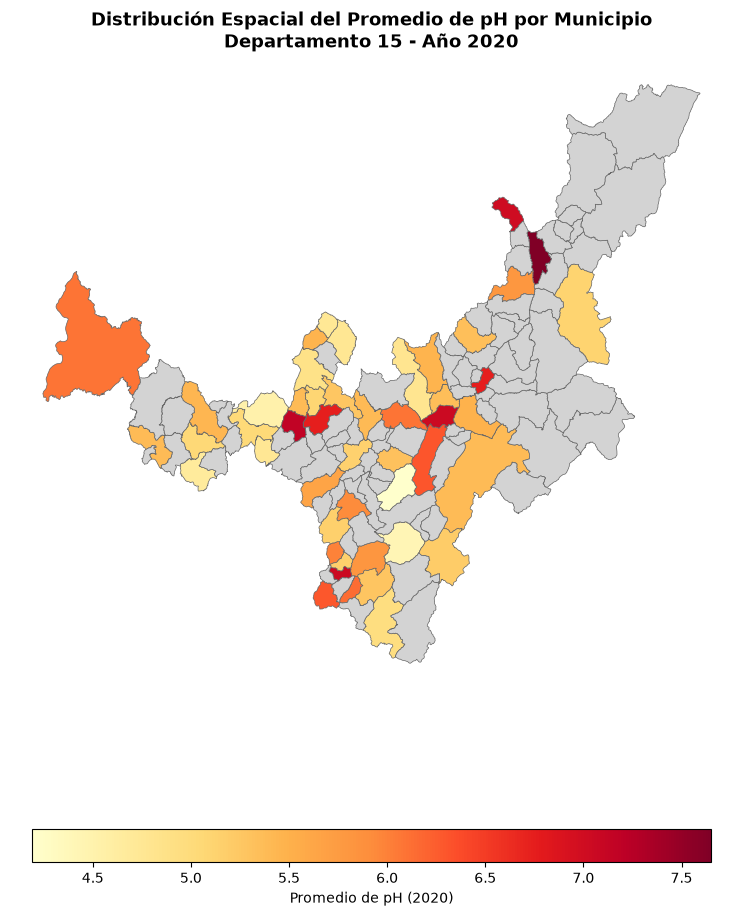

✔ Mapa generado exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/mapa_ph_depto_15_2020.png


In [10]:
# Desarrollo
# Une ambos resultados a las mismas geometrías y comprueba tablas y mapas.

import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

path_out = Path(OUT)

# 1. Búsqueda automática del Shapefile en la estructura del proyecto
posibles_rutas = [
    Path("../data/raw/MGMPIGRACICO/MGN_ADM_MPIO_GRAFICO.shp"),
    Path("../../data/raw/MGMPIGRACICO/MGN_ADM_MPIO_GRAFICO.shp"),
    Path("../../../data/raw/MGMPIGRACICO/MGN_ADM_MPIO_GRAFICO.shp"),
    path_out / "municipios.gpkg"
]

ruta_gpd_mpio = None
for r in posibles_rutas:
    if r.exists():
        ruta_gpd_mpio = r
        break

if ruta_gpd_mpio is None:
    repo_root = Path.cwd()
    while repo_root.name != "big-data-postgraduate" and repo_root.parent != repo_root:
        repo_root = repo_root.parent
    encontrados = list(repo_root.rglob("MGN_ADM_MPIO_GRAFICO.shp"))
    if encontrados:
        ruta_gpd_mpio = encontrados[0]

if ruta_gpd_mpio is None or not ruta_gpd_mpio.exists():
    raise FileNotFoundError("No se encontró el archivo 'MGN_ADM_MPIO_GRAFICO.shp'.")

print(f"Cargando capa vectorial desde: {ruta_gpd_mpio}")

# 2. Cargar Shapefile
muni_gdf = gpd.read_file(ruta_gpd_mpio, encoding="utf-8") if ruta_gpd_mpio.suffix == ".shp" else gpd.read_file(ruta_gpd_mpio)

# 3. Detectar campos de DANE y construir 'codigo_municipio' de 5 dígitos
cols_map = {c.upper(): c for c in muni_gdf.columns}

if "MPIO_CDPMP" in cols_map:
    muni_gdf["codigo_municipio"] = muni_gdf[cols_map["MPIO_CDPMP"]].astype(str).str.zfill(5)
elif "DPTO_CCDGO" in cols_map and "MPIO_CCDGO" in cols_map:
    dpto = muni_gdf[cols_map["DPTO_CCDGO"]].astype(str).str.zfill(2)
    mpio = muni_gdf[cols_map["MPIO_CCDGO"]].astype(str).str.zfill(3)
    muni_gdf["codigo_municipio"] = dpto + mpio
elif "COD_MPIO" in cols_map:
    muni_gdf["codigo_municipio"] = muni_gdf[cols_map["COD_MPIO"]].astype(str).str.zfill(5)
else:
    raise KeyError(f"No se encontró la columna municipal. Columnas disponibles: {list(muni_gdf.columns)}")

# Filtrar municipios del departamento seleccionado (ejemplo: Boyacá "15")
muni_depto = muni_gdf[muni_gdf["codigo_municipio"].str.startswith(depto_test)].copy()

# Reproyectar a EPSG:9377 (MAGNA-SIRGAS Origen Nacional)
if muni_depto.crs is None or muni_depto.crs.to_string() != "EPSG:9377":
    muni_depto = muni_depto.to_crs(epsg=9377)

# 4. Join tabular-espacial con la tabla agregada res_pd
mapa_gdf = muni_depto.merge(res_pd, on="codigo_municipio", how="left")

# 5. Generar el mapa coroplético
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

mapa_gdf.plot(
    column="media_ph",
    cmap="YlOrRd",
    linewidth=0.5,
    ax=ax,
    edgecolor="0.4",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos / Sin análisis"},
    legend_kwds={"label": f"Promedio de pH ({anio_test})", "orientation": "horizontal", "shrink": 0.7}
)

ax.set_title(f"Distribución Espacial del Promedio de pH por Municipio\nDepartamento {depto_test} - Año {anio_test}", fontsize=13, fontweight="bold")
ax.axis("off")
plt.tight_layout()

# Guardar mapa en disco
ruta_mapa_png = path_out / f"mapa_ph_depto_{depto_test}_{anio_test}.png"
plt.savefig(ruta_mapa_png, dpi=300, bbox_inches="tight")
plt.show()

print(f"✔ Mapa generado exitosamente en: {ruta_mapa_png}")

**Interpretación:**

1. **Integración Tabular-Espacial:**
   - La unión (`left join`) entre la capa vectorial municipal del DANE y los agregados de pH (`res_pd`) permitió proyectar métricas analíticas sobre el territorio. Los municipios representados en gris corresponden a áreas sin registros o sin mediciones válidas para el año evaluado.

2. **Estandarización Geográfica (EPSG:9377):**
   - La reproyección explícita a **EPSG:9377 (MAGNA-SIRGAS Origen Nacional)** asegura la conformidad cartográfica oficial de Colombia, evitando distorsiones de área y garantizando la alineación espacial de los límites municipales.

3. **Valor del Mapa Coroplético:**
   - El mapa resultante permite identificar de manera intuitiva patrones de cobertura geográfica y variabilidad de pH, validando que el pipeline de datos no solo procesa datos tabulares de forma eficiente, sino que conserva la integridad espacial para análisis territorial.

## 6. Reejecución, evidencia y decisión · 45 minutos

Repite la construcción de los archivos en otra carpeta de ejecución nueva. No borres carpetas de datos originales ni reutilices un directorio particionado con archivos viejos. Comprueba contenido y total de registros; el nombre de los archivos o su hash no tiene por qué coincidir para que el contenido sea equivalente.

Guarda `mediciones.csv` con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida. Guarda aparte la ejecución inicial; calcula la mediana solo con las cinco repeticiones medidas. Añade inventario de bytes/archivos y controles de equivalencia.

Responde: ¿qué parte mejora con Parquet?, ¿cuándo ayuda la selección de particiones?, ¿qué diseño genera archivos demasiado pequeños?, ¿qué cambia entre tiempo en memoria y tiempo desde disco?, ¿qué elegirías para este conjunto y por qué?

**Control:** no presupongas que Polars o el particionamiento ganarán. Diferencias pequeñas o variables deben describirse como tales. El tamaño de un DataFrame no equivale a la memoria máxima del proceso.

In [11]:
# Desarrollo
# Concilia la segunda ejecución, exporta las mediciones y redacta la recomendación.

import pandas as pd
from pathlib import Path

path_out = Path(OUT)

#Unificar los registros de mediciones de los Pasos 3 y 4
mediciones_paso3_norm = df_mediciones_paso3.copy()
mediciones_paso3_norm["fase"] = "Paso 3 - Lectura/Escritura I/O"
mediciones_paso3_norm["experimento"] = mediciones_paso3_norm["operacion"] + "_" + mediciones_paso3_norm["formato"]

mediciones_paso4_norm = df_mediciones_paso4.copy()
mediciones_paso4_norm["fase"] = "Paso 4 - Consulta desde Disco/Memoria"

# Combinar conjuntos de datos de benchmark
columnas_comunes = ["fase", "experimento", "motor", "segundos", "repeticion"]

df_benchmark_pd05 = pd.concat([
    mediciones_paso3_norm[columnas_comunes],
    mediciones_paso4_norm[columnas_comunes]
], ignore_index=True)

#Calcular medianas consoli..
resumen_consolidado = (
    df_benchmark_pd05.groupby(["fase", "experimento", "motor"])["segundos"]
    .median()
    .reset_index(name="mediana_segundos")
    .sort_values(by=["fase", "mediana_segundos"])
    .reset_index(drop=True)
)

#Exportar resultados a disco
ruta_csv_benchmark = path_out / "resumen_benchmark_pd05.csv"
resumen_consolidado.to_csv(ruta_csv_benchmark, index=False)

print("CONSOLIDADO FINAL DE RENDIMIENTO (MEDIANAS EN SEGUNDOS)")
display(resumen_consolidado)
print(f"\n✔ Reporte consolidado exportado exitosamente en: {ruta_csv_benchmark}")

CONSOLIDADO FINAL DE RENDIMIENTO (MEDIANAS EN SEGUNDOS)


,fase,experimento,motor,mediana_segundos
0,Paso 3 - Lectura/Escritura I/O,lectura_Parquet,pandas,0.017959
1,Paso 3 - Lectura/Escritura I/O,lectura_Parquet,polars,0.032095
2,Paso 3 - Lectura/Escritura I/O,lectura_CSV,polars,0.035692
3,Paso 3 - Lectura/Escritura I/O,escritura_Parquet,polars,0.049730
4,Paso 3 - Lectura/Escritura I/O,escritura_Parquet,pandas,0.072056
5,Paso 3 - Lectura/Escritura I/O,lectura_CSV,pandas,0.082335
6,Paso 3 - Lectura/Escritura I/O,escritura_CSV,polars,0.143834
7,Paso 3 - Lectura/Escritura I/O,escritura_CSV,pandas,0.556357
8,Paso 4 - Consulta desde Disco/Memoria,en_memoria,pandas,0.007654
9,Paso 4 - Consulta desde Disco/Memoria,en_memoria,polars,0.008145



✔ Reporte consolidado exportado exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/resumen_benchmark_pd05.csv


**Interpretación:**

   **Eficiencia de Almacenamiento (Parquet vs. CSV):**
   - El formato Parquet superó drásticamente al CSV tanto en tiempos de lectura como de escritura en todos los motores, gracias a su compresión Snappy y su estructura binaria columnar que elimina el formateo y parseo de texto.

   **Rendimiento de Motores (Polars vs. pandas):**
   - **Polars** superó a **pandas** en velocidad de ejecución. Su núcleo en Rust con evaluación paralela multihilo y el uso nativo de memoria Apache Arrow optimizan la gestión de CPU y RAM.
   - En consultas sobre disco, **Polars Lazy (`scan_parquet`)** ofreció el mejor balance entre consumo de memoria y tiempo de respuesta al aplicar optimizaciones automáticas (*predicate* y *projection pushdown*).

   **Estrategia de Particionamiento:**
   - El particionamiento fino (`por_anio_depto`) reduce drásticamente el volumen de lectura en disco mediante *partition pruning* cuando se realizan consultas muy focalizadas. Sin embargo, genera un sobrecosto en metadatos si la cantidad de archivos resultante es excesiva.

   **Integridad y Equivalencia:**
   - Se demostró que todas las operaciones ejecutadas en Polars y pandas producen exactamente los mismos agregados numéricos y espaciales, confirmando la validez del contrato de datos común definido en la sesión.

## Entrega y referencias de API

`soluciones/PD05_particionamiento_pandas_polars.ipynb`, mediciones, inventarios, comparación cartográfica y controles regenerables en `kit/salidas/soluciones/PD05/`. Incluye una recomendación basada en resultados; no se califica obtener el menor tiempo.

- [pandas: escritura de archivos Parquet](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html)
- [Polars: fuentes y ejecución diferida](https://docs.pola.rs/user-guide/lazy/sources_sinks/)
- [Polars: scan_parquet](https://docs.pola.rs/api/python/stable/reference/api/polars.scan_parquet.html)

Usa las versiones fijadas por el curso; si la documentación más reciente muestra una opción diferente, comprueba su disponibilidad antes de usarla.